# CatalogIQ - Notebook 04: Writing grounded product listings

**The business problem.** A small seller uploads a photo and wants a ready-to-publish listing: title, five bullet points,
description and search tags. If the writer is a language model left alone, it happily invents things ("100% cotton",
"waterproof", a brand that is not on the product). Invented facts cause returns and complaints. So this notebook asks one
question: **does giving the model real, well-rated example listings and a style guide (retrieval-augmented generation, RAG)
make the listing better and safer, or not?**

**How to read it.** Every step says WHAT we did, WHY it matters to the business and WHAT WE LEARNED. All numbers in the
"learned" boxes were printed by the code just above them. All logic lives in `src/catalogiq/rag/`; the notebook only calls it.

**Honest scope.** 50 held-out products, a small local model (llama3.2:3b on a laptop CPU), and the same model also acts as
judge. Treat the results as a careful small study, not a benchmark.

In [1]:
import json, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from catalogiq.config import get_config, get_rag_config, resolve_path
from catalogiq.data.fashion import image_path
from catalogiq.rag.evaluate import load_brand_lexicon, rescore_reports, retrieval_hit, summarise_run
from catalogiq.rag.eval_retrieval import evaluate_retrieval, load_queries, relevance_mask, summarise
from catalogiq.rag.knowledge_base import load_listings
from catalogiq.rag.retrieval import HybridRetriever

pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
cfg = get_rag_config()
OUT = resolve_path(cfg["paths"]["eval_dir"])

## 1. The knowledge base: real listings to learn from

**What we did.** The 800 Amazon Fashion listings from Phase 1 became the knowledge base. One listing is one document (title +
bullet features + description) with metadata (brand, rating, listing-quality score, category). The Amazon `categories` field is
empty for every item, so each listing was assigned a category group from keywords in its title (rules in `configs/rag.yaml`).
Documents are turned into 384-number vectors by the small `all-MiniLM-L6-v2` model (about 90 MB, runs fast on a CPU; with only
800 short English documents a bigger model would add time, not accuracy) and stored in a local ChromaDB. A category style guide
(`docs/style_guide.md`, generated from the same config the checks use) is indexed too.

**Why.** The generator should imitate how good listings are written for the *same kind* of product, and follow the marketplace
rules, instead of improvising.

In [2]:
items = load_listings()
print(items["group"].value_counts().to_string())
print()
print("listings with a description:", int((items["description"].str.len() > 0).sum()), "of", len(items))
print("median bullet points per listing:", int(items["features"].map(len).median()))
print()
print(items.loc[items["group"] == "topwear", "doc"].iloc[0][:350])

group
jewellery          183
accessories         95
other               79
eyewear             77
topwear             69
costume_novelty     59
innerwear_socks     58
bags_wallets        48
watches             45
bottomwear          44
footwear            24
dresses_ethnic      19

listings with a description: 247 of 800
median bullet points per listing: 5

Russell Athletic Men's Dri-Power Fleece Hoodies & Sweatshirts, Moisture Wicking, Cotton Blend, Relaxed Fit, Sizes S-4X. Features: 50% Polyester, 50% Cotton; Imported; Pull On closure; Machine Wash; Medium-weight 9 oz fleece keeps in body heat so you can stay warm; Dri-Power moisture wicking technology keeps you dry; Muff pocket for storing phone, k


**What we learned:** The 800 listings split unevenly: jewellery has 183 and accessories 95, but footwear has only 24 and dresses/ethnic wear only 19, and 79 listings (10%) matched no category rule and sit in "other". Only 247 of 800 listings have a description, while the median listing has 5 bullet points, so the bullets are the richest text to learn from. The thin footwear and dress groups matter because 11 of our 50 test products are footwear and 4 are dresses/ethnic: for them the examples come from a small pool.

## 2. Retrieval: does mixing keyword search and meaning search help?

**What we did.** Two search methods, then a merge:
- **BM25** is classic keyword search: it rewards rare exact words ("925", "wayfarer", "UPF").
- **Vector search** compares meaning: "something warm for my hands" can find *gloves*.
- **Reciprocal rank fusion (RRF)** merges the two rankings by position, then a small boost favours listings with a high
  quality score. A category filter limits results to the product's category.

We built a small test of **30 queries** (10 keyword-style, 10 paraphrase-style, 10 mixed). A listing counts as relevant if its
title or bullets match a keyword rule that was written down before any ranker was run (`configs/retrieval_test_queries.yaml`).
One query (L10) was replaced before the final run because its brand did not exist in the data.

**Why.** The generator is only as good as the examples it is shown.

In [3]:
r = HybridRetriever()
res = evaluate_retrieval(r)               # default quality boost
res_nb = evaluate_retrieval(r, boost=0.0) # boost switched off
tab = summarise(res).round(3)
print(tab[["hit@3", "p@3", "hit@5", "p@5", "mrr"]].to_string())

2026-10-12 10:09:22,150 | INFO     | catalogiq.rag.knowledge_base | Loading embedder sentence-transformers/all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

                 hit@3    p@3  hit@5    p@5    mrr
         mode                                     
lexical  bm25    1.000  0.867  1.000  0.780  0.950
         hybrid  1.000  0.933  1.000  0.780  1.000
         vector  1.000  0.767  1.000  0.660  0.900
mixed    bm25    1.000  0.867  1.000  0.860  1.000
         hybrid  1.000  0.900  1.000  0.900  0.900
         vector  1.000  0.800  1.000  0.800  0.883
semantic bm25    0.700  0.533  0.800  0.480  0.653
         hybrid  0.800  0.633  0.800  0.660  0.800
         vector  0.900  0.800  0.900  0.780  0.833
ALL      bm25    0.900  0.756  0.933  0.707  0.868
         hybrid  0.933  0.822  0.933  0.780  0.900
         vector  0.967  0.789  0.967  0.747  0.872


In [4]:
print("--- same table with the quality boost switched OFF (overall only) ---")
print(summarise(res_nb).round(3).loc["ALL", ["hit@3", "p@3", "hit@5", "p@5", "mrr"]].to_string())
print()
print("mean listing quality score of the top 5 (overall):")
q = pd.DataFrame({"boost on": res.groupby("mode")["quality_top"].mean(), "boost off": res_nb.groupby("mode")["quality_top"].mean()}).round(3)
print(q.to_string())

--- same table with the quality boost switched OFF (overall only) ---
        hit@3    p@3  hit@5    p@5    mrr
mode                                     
bm25    0.900  0.767  0.933  0.727  0.873
hybrid  0.933  0.811  0.933  0.800  0.900
vector  0.967  0.778  0.967  0.733  0.911

mean listing quality score of the top 5 (overall):
        boost on  boost off
mode                       
bm25       0.828      0.810
hybrid     0.820      0.805
vector     0.822      0.806


In [5]:
# Paired view: on how many of the 30 queries is hybrid better / equal / worse than each single method (precision@5)?
piv = res.pivot(index="id", columns="mode", values="p@5")
rows = []
for other in ("bm25", "vector"):
    d = piv["hybrid"] - piv[other]
    rows.append({"hybrid vs": other, "hybrid better": int((d > 1e-9).sum()), "equal": int((d.abs() <= 1e-9).sum()), "hybrid worse": int((d < -1e-9).sum())})
print(pd.DataFrame(rows).to_string(index=False))
print()
print("queries where BOTH single methods score 0 at p@5, but hybrid does not:", int(((piv["bm25"] == 0) & (piv["vector"] == 0) & (piv["hybrid"] > 0)).sum()))
print("queries where hybrid scores 0 at p@5:", list(piv.index[piv["hybrid"] == 0]))

hybrid vs  hybrid better  equal  hybrid worse
     bm25             10     18             2
   vector              9     16             5

queries where BOTH single methods score 0 at p@5, but hybrid does not: 0
queries where hybrid scores 0 at p@5: ['S04', 'S05']


**What we learned:** Over all 30 queries, hybrid search had the best precision@5 (0.78 vs 0.747 for vector-only and 0.707 for keyword-only) and the best average first-hit rank (MRR 0.90 vs 0.872 and 0.868). It was clearly better than keyword search alone (better on 10 queries, worse on 2) and slightly better than vector search (better on 9, worse on 5). It did **not** win everything: vector search had the best hit rate at 3 (0.967 vs 0.933) and was best on paraphrase-style queries (precision@5 0.78 vs 0.66 for hybrid), where keyword search drags the merged list down. Keyword search was strongest when queries contained exact rare words. With only 30 queries these gaps are small, so the fair summary is: hybrid is the safest all-rounder, not a dramatic winner. Switching the quality boost on lifted the mean quality of the top 5 from 0.805 to 0.820 for hybrid but cost a little precision (0.800 to 0.780), a trade-off we accepted because the examples are meant to be well-rated listings.

## 3. The writer: prompt, validated JSON, retry

**What we did.** For each product the pipeline takes the photo, runs the Phase 2 classifier to get attributes with a confidence,
and builds a prompt (`configs/prompts/listing.yaml`): strict rules, the product facts (low-confidence ones marked UNCERTAIN),
optional seller notes, and - in RAG mode only - the style rules for the category plus three retrieved example listings. The model must answer
with JSON that is validated (title, exactly 5 bullets, description, tags, attributes used, warnings); if it is not valid, one repair
prompt is sent. The model runs locally through Ollama behind a small interface (`LLMClient`) so a hosted model can replace it later,
and identical requests are cached on disk.

**Why.** Structured, validated output means the app never has to guess how to display a listing.

In [6]:
products = pd.read_parquet(OUT / "products.parquet")
print(len(products), "held-out products from the Kaggle TEST split (never used for training)")
print(products["group"].value_counts().to_string())
print("products with a brand taken from the catalog name (used as a 'seller note'):", int(products["brand"].notna().sum()))

50 held-out products from the Kaggle TEST split (never used for training)
group
topwear            15
footwear           11
bags_wallets        5
dresses_ethnic      4
watches             3
innerwear_socks     3
bottomwear          3
beauty              2
accessories         2
eyewear             1
jewellery           1
products with a brand taken from the catalog name (used as a 'seller note'): 43


## 4. Guardrails: checking the writer instead of trusting it

**What we did.** After the model answers, rule-based checks run (`src/catalogiq/rag/guardrails.py`):
1. **Hallucination check** - any material (cotton, leather...), brand, claim (waterproof, machine wash...), number with a unit,
   or size in the listing that is *not* in the product facts or seller notes is flagged. Retrieved examples are deliberately **not**
   a source of facts: if the model copies "100% cotton" from an example, it is flagged.
2. **Banned words** - hype ("best", "perfect") and health claims.
3. **Style compliance** - title length, brand first, 5 bullets, description length, tag count, required parts in the title, no uncertain attribute in the title.
4. **Attribute coverage** - are the category's required attributes mentioned?

A fourth arm adds a **rewrite step**: if the checks find problems, they are sent back to the model once, and the rewrite is kept only
if it has fewer findings.

**Why.** The business cares about wrong claims reaching shoppers, so the safety net is deterministic code, not another model.

## 5. The experiment: 50 products, four ways of writing

**What we did.** Same 50 photos, same attributes, four arms: (a) **no-RAG**, (b) **RAG**, (c) no-RAG + rewrite, (d) RAG + rewrite.
All guardrail numbers below use the *same final checks* (earlier stored reports were re-scored). The judge is the same local model, prompted
with the saved rubric in `configs/prompts/judge.yaml` (scores 1-5 for clarity and accuracy).

**Disclosure.** After seeing the first results we fixed two metric bugs (confidence percentages and a few common words wrongly treated as
brands), added claim words (such as "quartz" and "high-quality") that the first run showed the model copying, and added the rewrite arm. These changes were made while looking at
these same 50 products, so the numbers are slightly optimistic for the final design.

In [7]:
summary = json.loads((OUT / "summary.json").read_text())
S = pd.DataFrame(summary).T
S.insert(0, "arm", ["no-RAG", "RAG", "no-RAG + rewrite", "RAG + rewrite"])
cols = ["arm", "valid_json_rate", "attribute_coverage", "hallucination_rate", "unsupported_per_listing", "banned_rate", "style_compliance", "judge_clarity", "judge_accuracy", "retrieval_hit_rate", "latency_mean_s"]
print(S[cols].round(3).to_string())

                         arm  valid_json_rate  attribute_coverage  hallucination_rate  unsupported_per_listing  banned_rate  style_compliance  judge_clarity  judge_accuracy  retrieval_hit_rate  latency_mean_s
no_rag                no-RAG              1.0                 1.0                0.02                     0.02         0.14              0.00           3.32            3.70                 NaN          12.842
rag                      RAG              1.0                 1.0                0.70                     1.22         0.70              0.02           2.86            4.26                0.96          43.836
no_rag_fix  no-RAG + rewrite              1.0                 1.0                0.00                     0.00         0.02              0.00           3.44            3.68                 NaN          35.867
rag_fix        RAG + rewrite              1.0                 1.0                0.40                     0.60         0.32              0.16           2.84        

In [8]:
lex = load_brand_lexicon()
recs = {m: rescore_reports(pd.DataFrame([json.loads(l) for l in open(OUT / f"gen_{m}.jsonl")]), lex) for m in ["no_rag", "rag", "no_rag_fix", "rag_fix"]}
from collections import Counter
print("What kind of unsupported fact? (count of listings containing it)")
kinds = {m: Counter(k.split(":")[0] for u in pd.DataFrame(list(r[r.ok].report))["unsupported"] for k in set(x.split(":")[0] for x in u)) for m, r in recs.items()}
print(pd.DataFrame(kinds).fillna(0).astype(int).to_string())
print()
top = {m: Counter(x for u in pd.DataFrame(list(r[r.ok].report))["unsupported"] for x in u).most_common(6) for m, r in recs.items() if m in ("rag", "rag_fix")}
for m, v in top.items(): print(m, v)

What kind of unsupported fact? (count of listings containing it)
          no_rag  rag  no_rag_fix  rag_fix
claim          1   28           0       12
material       0   17           0       14
number         0    2           0        2

rag [('material:leather', 11), ('claim:high-quality', 10), ('claim:breathable', 6), ('claim:machine wash', 4), ('material:rubber', 3), ('claim:rubber sole', 3)]
rag_fix [('material:leather', 8), ('claim:high-quality', 3), ('material:stainless steel', 2), ('material:cotton', 2), ('claim:hand wash', 2), ('material:rubber', 1)]


In [9]:
print("Which style rules fail most? (listings out of 50)")
sv = {}
for m, r in recs.items():
    rep = pd.DataFrame(list(r[r.ok].report))
    c = Counter(v.split(":")[0] for vs in rep["style_violations"] for v in set(x.split(":")[0] for x in vs))
    sv[m] = c
print(pd.DataFrame(sv).fillna(0).astype(int).sort_values("rag", ascending=False).to_string())
print()
for m in ("no_rag_fix", "rag_fix"):
    r = recs[m]; print(m, "rewrite tried:", int(r["fix_attempts"].sum()), "rewrite kept:", int(r["fixed"].sum()))

Which style rules fail most? (listings out of 50)
                                no_rag  rag  no_rag_fix  rag_fix
uncertain_baseColour_in_title       22   31          19       27
description_words                   45   14          44       16
uncertain_usage_in_title             6    7           5        6
uncertain_articleType_in_title       4    4           4        4
title_missing_articleType            1    1           1        1
tag_count                           26    0          26        0
title_missing_gender                 4    0           1        0
brand_not_first                      5    0           5        0
title_order                         12    0          11        0
title_length                         3    0           3        0

no_rag_fix rewrite tried: 50 rewrite kept: 13
rag_fix rewrite tried: 50 rewrite kept: 31


**What we learned:** The most important finding is a negative one. Giving the 3B model real example listings made its output **less faithful**: 70% of RAG listings (35 of 50) contained at least one material or claim that was not in the inputs, against 2% (1 of 50) without retrieval. The copied facts were things like leather (11 listings), "high-quality" (10), breathable (6) and machine wash (4); 70% of RAG listings also used a banned hype word ("perfect" in 35 of them), against 14% without retrieval. The guardrail rewrite helped but did not fix it: it cut RAG unsupported-fact listings from 70% to 40% and banned-word listings from 70% to 32%, and it was kept for 31 of 50 RAG listings, at a cost of about 2.3 times the time (100.6 s vs 43.8 s per listing on this CPU). What retrieval did improve is style: without the style guide the model broke the description-length rule in 45 of 50 listings and the tag-count rule in 26 of 50, while RAG broke them in 14 and 0 respectively; brand-first and title-order failures dropped from 5 and 12 to 0. Full style compliance stays low everywhere (0% to 16%) mainly because the classifier is often unsure of colour and the model still puts the unsure colour in the title (31 of 50 RAG titles). Retrieval itself worked: 96% of products got at least one example from the right category. Finally, notice that the judge scored RAG *higher* on accuracy (4.26 vs 3.70) even though the guardrail found far more invented facts in RAG, which is the first sign the judge cannot be trusted on accuracy.

## 6. Can we trust the judge? Your hand-check of 10 listings

**What we did.** The project owner rated 10 listings (different products, arm hidden) for clarity and accuracy on the same 1-5 scale,
and left notes on what was wrong. We compare those ratings with the judge model and with the guardrail.

**Why.** An automatic judge is only useful if it agrees with a person. With 10 items this is a sanity check, not a statistic.

In [10]:
hc = pd.read_csv(OUT / "handcheck_vs_judge.csv")
print(hc.rename(columns={"unsup": "unsupported facts (guardrail)"}).to_string(index=False))
from scipy.stats import spearmanr
for a, b in (("human_c", "judge_c"), ("human_a", "judge_a")):
    rho = spearmanr(hc[a], hc[b])
    print(f"{a} vs {b}: Spearman {rho.statistic:.2f} (p={rho.pvalue:.2f}), exact agreement {(hc[a] == hc[b]).mean():.0%}, within 1 point {((hc[a]-hc[b]).abs() <= 1).mean():.0%}, mean human {hc[a].mean():.1f} vs judge {hc[b].mean():.1f}")
print()
print(hc.groupby("mode")[["human_c", "human_a", "judge_c", "judge_a"]].mean().round(2).to_string())

 item    mode  judge_c  judge_a  unsupported facts (guardrail)  banned  style  human_c  human_a
    1     rag        2        3                              0       0      3        5        3
    2  no_rag        3        3                              0       0      4        4        3
    3  no_rag        4        3                              0       0      4        4        3
    4 rag_fix        3        3                              3       0      2        5        5
    5     rag        3        5                              2       1      0        4        3
    6     rag        3        5                              3       1      2        5        5
    7     rag        3        5                              3       1      1        4        3
    8 rag_fix        3        3                              0       0      2        3        1
    9  no_rag        3        3                              0       0      1        5        3
   10 rag_fix        3        5         

**What we learned:** On 10 listings the model judge and the human rater barely agreed. For accuracy, exact agreement was 50% and the rank correlation was 0.00; for clarity it was 20% exact and -0.33. The judge was on average 0.8 points more generous on accuracy (3.8 vs 3.0) and 1.1 points harsher on clarity (3.0 vs 4.1). With n=10 none of this is statistically firm, but it supports not using the 3B judge as the deciding metric. The human notes explain much of the low accuracy: in items 1, 2, 3, 5, 7 and 9 the classifier's colour, season or usage was wrong or unsure (for example black shoes predicted green, a purple saree predicted blue), and in items 8 and 10 the seller details (material, capacity, lens, weight) were never supplied, so the listing could only say "please confirm". Two caveats we found while checking: item 6 (RAG) was rated 5 for accuracy by the human although the guardrail flagged three unsupported facts in it (cotton, hand wash, 4 pack, all copied from an example), and the page asked the rater to judge against the facts shown rather than the photo, which is hard to do in practice. The by-arm averages (3 to 4 items each) are anecdotes, not evidence.

## 7. Three products side by side

**What we did.** Three held-out products, each shown as: the photo and what the classifier concluded -> the no-RAG listing -> the RAG listing.
The examples are chosen to show different outcomes (not only the best ones).

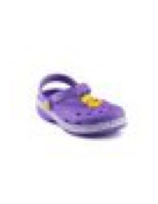

CATALOG NAME: Warner Bros Kids Girls TW Big Facelog Purple Sandals | catalog truth: Sandals Purple Fall Casual
CLASSIFIER  : {'articleType': ('Sandals', 0.65, 'ok'), 'baseColour': ('Purple', 0.56, 'UNSURE'), 'usage': ('Casual', 0.91, 'ok'), 'season': ('Fall', 0.58, 'UNSURE')}
SELLER NOTES: {'brand': 'Warner Bros'}

--- NO-RAG (judge clarity 3, accuracy 3; unsupported: []; banned: [])
TITLE: Warner Bros Purple Sandals
 * Unisex design
 * Casual wear
 * Fall season suitable
 * Warner Bros brand
 * Sandals style
DESC : Warner Bros purple sandals for casual wear. Please confirm the base colour and season suitability.
TAGS : warner bros, purple sandals, fall sandals, casual sandals

--- RAG (judge clarity 3, accuracy 3; unsupported: ['material:leather', 'material:rubber', 'claim:rubber sole']; banned: [])
TITLE: Warner Bros Unisex Sandals, Casual, Purple
 * Leather upper
 * Rubber sole
 * Please confirm base colour
 * Please confirm season
 * Casual wear
DESC : Warner Bros unisex sandals fo

In [11]:
judged = {m: pd.read_pickle(OUT / f"judged_{m}.pkl").set_index("id") for m in ("no_rag", "rag")}
R = {m: recs[m].set_index("id") for m in ("no_rag", "rag")}
unsup = lambda m, i: len(R[m].loc[i, "report"]["unsupported"])
cand = [i for i in products["id"] if R["no_rag"].loc[i, "ok"] and R["rag"].loc[i, "ok"]]
leak = [i for i in cand if unsup("rag", i) >= 3 and unsup("no_rag", i) == 0]
clean = [i for i in cand if unsup("rag", i) == 0 and unsup("no_rag", i) == 0]
both = [i for i in cand if unsup("rag", i) >= 1 and unsup("no_rag", i) >= 1]
picks = [leak[0], clean[0], (both or leak[1:])[0]]
def show(pid):
    row = products.set_index("id").loc[pid]
    a = R["rag"].loc[pid, "attributes"]
    fig, ax = plt.subplots(figsize=(2.4, 2.4)); ax.imshow(Image.open(image_path(resolve_path(get_config()["data"]["fashion"]["images_dir"]), int(pid)))); ax.axis("off"); plt.show()
    print("CATALOG NAME:", row["productDisplayName"], "| catalog truth:", row["articleType"], row["baseColour"], row["season"], row["usage"])
    print("CLASSIFIER  :", {k: (a[k][0], round(a[k][1], 2), "UNSURE" if a[k][2] else "ok") for k in ("articleType", "baseColour", "usage", "season")})
    print("SELLER NOTES:", R["rag"].loc[pid, "notes"])
    for m, label in (("no_rag", "NO-RAG"), ("rag", "RAG")):
        l = R[m].loc[pid, "listing"]; rep = R[m].loc[pid, "report"]
        print(f"\n--- {label} (judge clarity {judged[m].loc[pid,'judge_clarity']:.0f}, accuracy {judged[m].loc[pid,'judge_accuracy']:.0f}; unsupported: {rep['unsupported']}; banned: {rep['banned']})")
        print("TITLE:", l["title"]); [print(" *", b) for b in l["bullets"]]; print("DESC :", l["description"]); print("TAGS :", ", ".join(l["search_tags"]))
for p in picks[:1]: show(p)

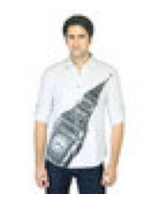

CATALOG NAME: Provogue Men Printed White Shirt | catalog truth: Shirts White Fall Casual
CLASSIFIER  : {'articleType': ('Shirts', 0.48, 'UNSURE'), 'baseColour': ('White', 0.62, 'UNSURE'), 'usage': ('Casual', 0.53, 'UNSURE'), 'season': ('Fall', 0.73, 'UNSURE')}
SELLER NOTES: {'brand': 'Provogue'}

--- NO-RAG (judge clarity 3, accuracy 5; unsupported: []; banned: [])
TITLE: Provogue Men's Casual Shirt
 * Brand: Provogue
 * Article Type: Shirts
 * Base Colour: White
 * Usage: Casual
 * Season: Fall
DESC : Provogue Men's Casual Shirt. Please confirm the article type, base colour, usage, and season as the provided information is uncertain.
TAGS : provogue, men's casual shirt, fall fashion

--- RAG (judge clarity 2, accuracy 3; unsupported: []; banned: [])
TITLE: Provogue Men's Shirt, Casual, White
 * Material: please confirm
 * Style: Casual
 * Colour: please confirm
 * Season: Fall
 * Fit: please confirm
DESC : Provogue Men's Shirt, Casual, White. This shirt is part of Provogue's collectio

In [12]:
show(picks[1])

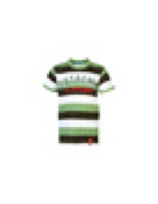

CATALOG NAME: Gini and Jony Kids Boys Stripes Green Tshirts | catalog truth: Tshirts Green Fall Casual
CLASSIFIER  : {'articleType': ('Tshirts', 0.92, 'ok'), 'baseColour': ('Green', 0.37, 'UNSURE'), 'usage': ('Casual', 0.85, 'ok'), 'season': ('Summer', 0.51, 'UNSURE')}
SELLER NOTES: {'brand': 'Gini and Jony'}

--- NO-RAG (judge clarity 3, accuracy 5; unsupported: ['claim:authentic']; banned: [])
TITLE: Gini and Jony Green Casual T-Shirt for Boys
 * For boys aged [age range]
 * Made from [material] fabric
 * Casual wear suitable for summer
 * Available in [size range]
 * Authentic Gini and Jony product
DESC : Gini and Jony Green Casual T-Shirt for Boys. Please confirm the base colour and season. (please confirm: base colour: Green, season: Summer). Authentic Gini and Jony product.
TAGS : gini and jony, green t-shirt, boys casual wear, summer fashion

--- RAG (judge clarity 3, accuracy 3; unsupported: ['claim:high-quality']; banned: ['perfect'])
TITLE: Gini and Jony Boys T-Shirt, Casual,

In [13]:
show(picks[2])

**What we learned:** Three products, three different stories. *Sandals:* the no-RAG listing is short and safe; the RAG listing invents "leather upper" and "rubber sole" (copied from example listings) while correctly flagging the uncertain colour and season. *Shirt:* the classifier was unsure of all four attributes; neither listing invents facts, but both are mostly "please confirm" with little selling value, and the no-RAG bullets just repeat attribute names. *T-shirt:* no-RAG leaves unfilled placeholders such as "[material]" and "[size range]" in the bullets, which would be embarrassing if published; RAG writes fluent bullets but adds "high-quality fabric" and "perfect". Neither mode is publish-ready without checks, which is what the guardrails are for.

## 8. What this means, and what we would do next

**Conclusions.**
1. **Retrieval works; retrieved *listings* are the problem.** The right category came back 96% of the time, and the style guide fixed length, tag-count and title-order rules. But a 3B model treats example listings as a source of facts, and 70% of RAG listings contained an unsupported material or claim.
2. **Guardrails are essential, not optional.** The deterministic check found what the judge missed; a guardrail-triggered rewrite cut unsupported-fact listings from 70% to 40% but doubled the time per listing.
3. **Input quality limits output quality.** Many human complaints came from the classifier (colour, season, usage) and from missing seller details, so the app should let sellers confirm attributes and enter material, size and weight before generating.
4. **The judge is not trustworthy here.** Same model as writer, weak agreement with the human (10 items). Use the deterministic checks as the primary metric and a human sample for quality.

**Next experiments (not run):** (a) show the model only the *style guide* and the structure of examples with their facts removed, (b) try a larger local model or a hosted one behind the same `LLMClient` interface, (c) generate the title with a fixed template from confident attributes and use the model only for bullets and description, (d) re-run on fresh products so the design is not tuned on the same 50.

**Limitations.** 50 products and 30 retrieval queries; same model as writer and judge; seller notes were only a brand taken from the catalog name; the guardrail word lists are finite (a novel invented claim can slip through, and some flags can be false alarms); the metric fixes and the rewrite arm were added after looking at these 50 products.